# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Domingo, Judiele Fatima P.
- _Student No._: 2023-05167
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="errorplotf.png" alt="absolute error vs n for f(x)" width=30%> <img src="errorplotg.png" alt="absolute error vs n for g(x)" width=30%> <img src="errorploth.png" alt="absolute error vs n for h(x)" width= 30%>

**Figure 1:** $\lvert$error vs. n$\rvert$ of Trapezoidal integration and Simpson's rule for f(x), g(x), h(x)

<img src="mcf.png" alt="Monte Carlo Plot for f(x)" width=30%> <img src="mcg.png" alt="Monte Carlo Plot for g(x)" width=30%> <img src="mch.png" alt="Monte Carlo Plotfor h(x)" width= 30%>

**Figure 2:** Plotted Monte Carlo integrals for f(x), g(x), h(x); Red, data points outside the bounds of x, blue: data points within bounds



### Report discussion

Figure 1 shows trapezoidal rule as the most consistent method with error decreasing as n increases, the Simpson's rules on the other hand swing from either really low error or high error due to polynomial overshoots. It also struggles with end-point derivative singularities on functions like f(x) and h(x) thus the linear trapezoidal rule appears as the most consistent out of the 3 methods. Figure 2 shows a hit-or-miss plot of Monte Carlo integration. Points outside the bounded box are colored red while points inside the bounded box are colored blue.

Monte Carlo simulation estimates an integral based on the Law of Large Numbers by taking the average value of randomly sampled points across the integration interval. In hit-or-miss sampling, it works because the probability of a random point landing inside the bounded region under the curve is directly proportional to the ratio of the integrand's area to the bounding box's area.

Newton-Cotes methods are better suited for low-dimensional functions (less than 3 dimensions) because of their error functions $O(N^{-2}),O(N^{-4})
$ while Monte Carlo is better for multi-dimensional functions or functions with messy boundaries due to its error function $O(N^{-\frac{1}{2}})$


### Other comments
- N/A
- 

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
#Test functions
def f(x): #x=0, x=3/2
    return np.sqrt(9-4*x**2)
def g(x): #x=-2, x=2
    return -x**2+1
def h(x): #x=0. x= pi
    return np.cos(x)*np.sqrt(x)

In [3]:
#integration functions from Gezerlis
#f = function, a,b = are boundary values, n=no. of points/divisions
def trapezoid (f,a,b,n): #1/2[f(0)+f(n-1)]+ sum of f(i) from i=1 to i=n-2
    h = (b-a)/(n-1) #height/grid spacing
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0]=0.5; cs[-1]=0.5
    contribs = cs*f(xs) #boundary values f(0) and f(n-1) are multiplied by 1/2
    total_area = h * np.sum(abs(contribs))
    signed_integral = h*np.sum(contribs) 
    return total_area, signed_integral
    
def simpson_thirds (f,a,b,n): #weights = h/3[1,4,2,4,...,2,4,1]
    h = (b-a)/(n-1) #grid spacing
    xs = a+np.arange(n)*h
    cs= 2*np.ones(n)
    cs[1::2] =4; cs[0] = 0.5; cs[-1]=1
    contribs = cs*f(xs)
    total_area = (h/3)*np.sum(abs(contribs))
    signed_integral = (h/3)*np.sum(contribs)
    return total_area, signed_integral

def simpson_three_eighths (f,a,b,n):#weights = 3/8*[1,3,3,2,..., ]
    h = (b-a)/(n-1)
    xs = a+np.arange(n)*h
    cs = np.full(n,3)#creates an array of all 3s
    cs[0] = 1; cs[-1] = 1 # boundaries are 1
    cs[3:-1:3] = 2 # every third element is 2
    contribs = cs*f(xs)
    signed_integral = (3*h/8) *np.sum(contribs)
    total_area = (3*h/8)*np.sum(abs(contribs))
    return total_area, signed_integral
    
def montecarlo(f, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)
    
    if option == "uniform":
        fs_signed = f(us)
        fs_area = np.abs(f(us))
        
        signed_integral = (b - a) * np.mean(fs_signed)
        total_area = (b - a) * np.mean(fs_area)
        return total_area, signed_integral
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
    
        us = np.random.uniform(0, 1, n)
    
        xs = (-c0 + np.sqrt(c0**2 + 2 * c1 * us)) / c1
        xs = a + (b - a) * xs   # only keep this if xs is truly in [0,1]
    
        weights = (c0 + c1 * xs) / (b - a)
    
        fs_signed = f(xs) / weights
        fs_area = np.abs(f(xs)) / weights
    
        signed_integral = np.mean(fs_signed)
        total_area = np.mean(fs_area)
        return total_area, signed_integral

##### TESTING INTEGRATION FUNCTIONS

---

In [4]:
quad(f,0,3/2)

(3.534291735288518, 3.9752112712676535e-10)

In [5]:
trapezoid(f,0,3/2,100)

(3.5329490753789425, 3.5329490753789425)

In [6]:
simpson_thirds(f,0,3/2,100)

(3.524555390710883, 3.524555390710883)

In [7]:
simpson_three_eighths(f,0,3/2,100)

(3.5336527868794434, 3.5336527868794434)

In [8]:
montecarlo(f,0,3/2,100)

(3.4153425082722664, 3.4153425082722664)

In [9]:
quad(g,-2,2)

(-1.3333333333333335, 4.465845366792915e-14)

In [10]:
trapezoid(g,-2,2,100)

(4.001228487301338, -1.3344216576539822)

In [11]:
simpson_thirds(g,-2,2,100)

(3.940622426695278, -1.2738155970479215)

In [12]:
simpson_three_eighths(g,-2,2,100)

(4.000018550982739, -1.3333333333333341)

In [13]:
montecarlo(g,-2,2,100)

(4.227792366260232, -1.7560467770983343)

In [14]:
quad(h,0,np.pi)

(-0.8948314694841447, 5.742084585591556e-11)

In [15]:
trapezoid(h,0,np.pi,100)

(2.3018606389900764, -0.8960303293102408)

In [16]:
simpson_thirds(h,0,np.pi,100)

(2.2838531166782006, -0.8765891124278938)

In [17]:
simpson_three_eighths(h,0,np.pi,100)

(2.3023482742748436, -0.8953901116806321)

In [18]:
montecarlo(h,0,np.pi,100)

(2.5027271683277053, -1.1141350182769656)

#### PLOTTING TRAPEZOID & SIMPSONS

In [19]:
#function to run diff integration methods and calculate error on the 3 f,g,h with varying step sizes
def error_plot (f,a,b,n, title):
    exact, _ = quad(f,a,b)
    trapezoid_error = []
    simpson1_error = []
    simpson2_error = []
    for steps in n: #evaluates integrals
        _, trap = trapezoid(f,a,b,steps)
        _, simp1 = simpson_thirds(f,a,b,steps)
        _, simp2 = simpson_three_eighths(f,a,b,steps)

    #calculates errors
        trapezoid_error.append(abs(trap-exact))
        simpson1_error.append(abs(simp1-exact))
        simpson2_error.append(abs(simp2-exact))

    #Plotting
    plt.scatter(n, trapezoid_error, marker='o', label='Trapezoidal Integration')
    plt.scatter(n, simpson1_error, marker='s', label="Simpson's 1/3 rule")
    plt.scatter(n, simpson2_error, marker = '^', label = "Simpson's 3/8 rule")
    plt.yscale("log")
    plt.xscale("log")
    plt.xlabel('N')
    plt.ylabel('Absolute Error')
    plt.title(title)
    plt.legend()
    return plt.show()
    
N = np.logspace(1, 5, 100).astype(int)
N = np.unique(N)

/tmp/ipykernel_111544/2542076418.py:3: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(9-4*x**2)


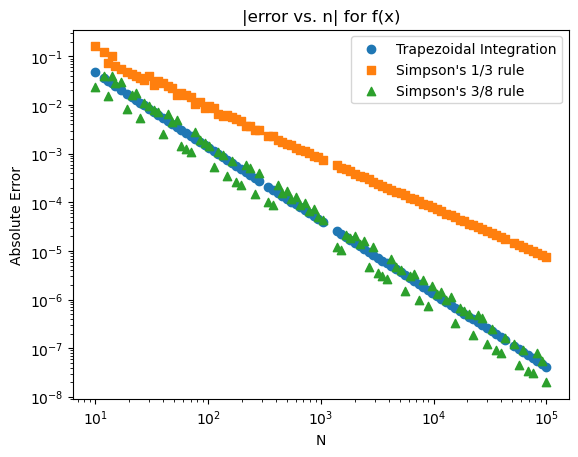

In [20]:
error_plot(f,0,3/2,N, title = "|error vs. n| for f(x)")

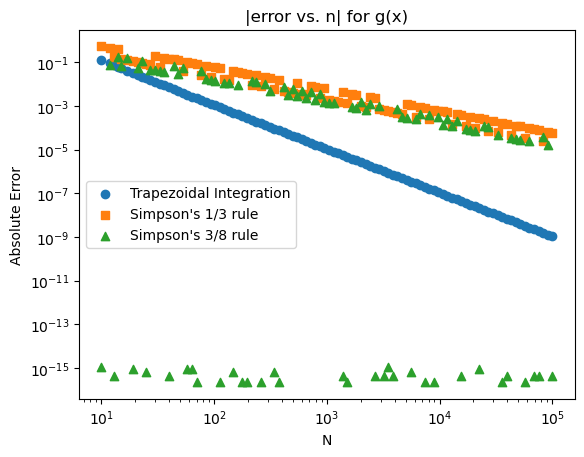

In [21]:
error_plot(g,-2,2,N, title = "|error vs. n| for g(x)")

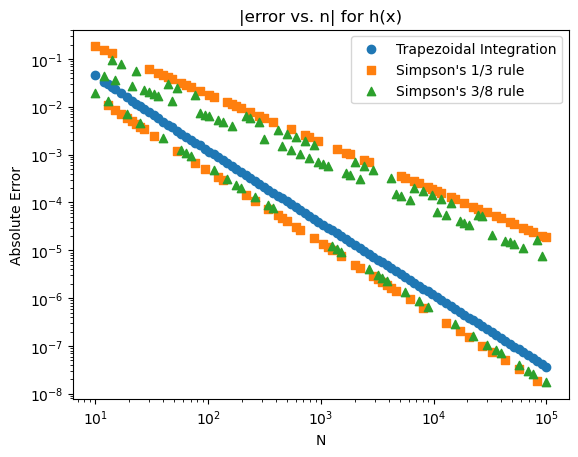

In [22]:
error_plot(h,0,np.pi,N,title = "|error vs. n| for h(x)")

#### PLOTTING MONTE CARLO

---

In [34]:
def montecarlo_plot(f, a, b, title, func, n=20000):
    #plotting grid
    x_curve = np.linspace(a, b, 1000)
    y_curve = f(x_curve)
    
    #calculates y range
    y_min = min(0, np.min(y_curve)) * 1.15
    y_max = max(0, np.max(y_curve)) * 1.15
        
    #sample random points
    x_rand = np.random.uniform(a, b, n)
    y_rand = np.random.uniform(y_min, y_max, n)
    
    #evaluates functions at sample points
    fx_rand = f(x_rand)

    #bounding conditions
    blue = (y_rand > 0) & (y_rand <= fx_rand)
    
    # Points below x-axis bounded above curve: f(x) <= y < 0
    red = (y_rand < 0) & (y_rand >= fx_rand)
    
    # groups coords into red and blue
    x_blue, y_blue = x_rand[blue], y_rand[blue]
    x_red, y_red = x_rand[red], y_rand[red]
    
    #plotting
    plt.figure(figsize=(11, 6), dpi=100)
    # Scatter plot bounded point
    if len(x_blue) > 0:
        plt.scatter(x_blue, y_blue, color='blue', s=2, alpha=0.6, label='Positive Area (f(x) > 0)')
    if len(x_red) > 0:
        plt.scatter(x_red, y_red, color='red', s=2, alpha=0.6, label='Negative Area (f(x) < 0)')
    plt.plot(x_curve, y_curve, color='black', linewidth=2, label='$f(x)$')
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.axvline(a, color='gray', linestyle=':', label='x-bounds')
    plt.axvline(b, color='gray', linestyle=':')
    
    plt.title(title)
    plt.xlabel('x')
    plt.ylabel(func)
    plt.legend(loc='upper right')
    return plt.show()

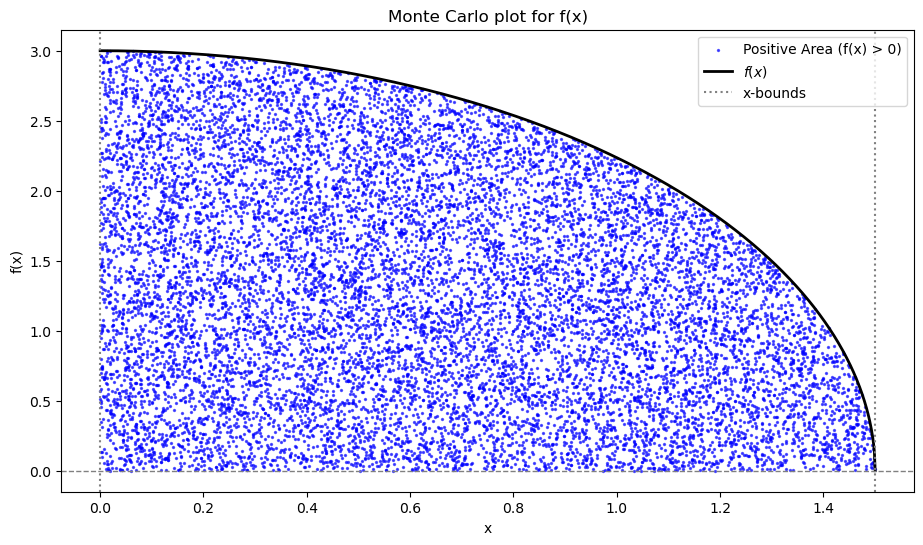

In [35]:
montecarlo_plot(f,0,3/2,title="Monte Carlo plot for f(x)", func="f(x)")

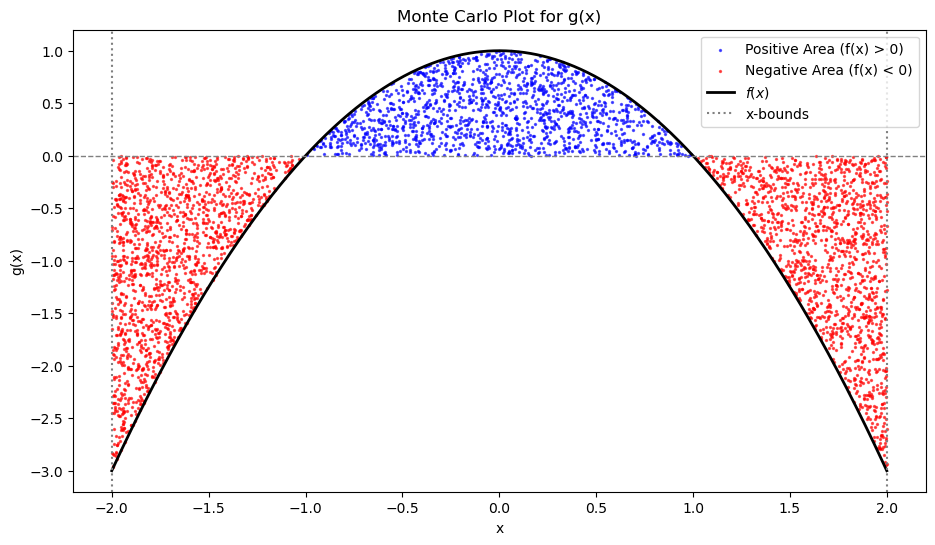

In [36]:
montecarlo_plot(g,-2,2,title="Monte Carlo Plot for g(x)", func="g(x)")

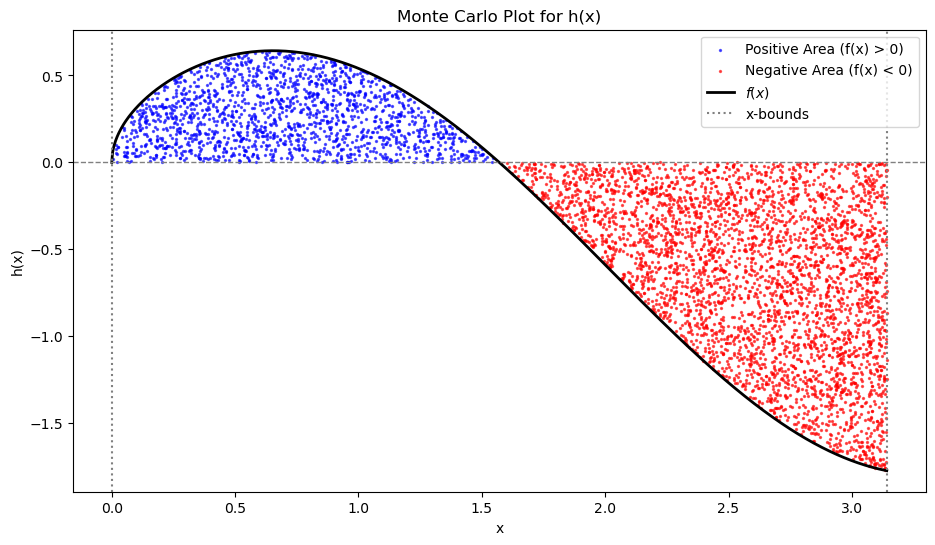

In [37]:
montecarlo_plot(h,0,np.pi,title="Monte Carlo Plot for h(x)", func="h(x)")